# Türkçe SMS Spam Tespiti

**Doğal Dil İşleme dersi proje çalışması**

Bu projede Türkçe SMS mesajlarını **spam** ve **normal** olarak sınıflandırıyorum. Derste gördüğümüz yöntemleri, dersin veri setlerinden farklı yeni bir probleme uyguluyorum:

| Bölüm | Yöntem | Dersteki karşılığı |
|---|---|---|
| 1–2 | Keşifsel veri analizi, Türkçe metin temizleme, tokenization | Ders 1 (Morfoloji), LAB1 |
| 3 | Sayma (counting) vektörleri ve TF-IDF | Ders 2–3, LAB1–2 |
| 4 | Markov dil modeliyle **sıfırdan yazılmış** Bayes sınıflandırıcı | Ders 4–5, LAB3–4, toy_bayes |
| 5 | Multinomial Naive Bayes (scikit-learn), Count ve TF-IDF karşılaştırması | LAB5 |
| 6 | Dengesiz veri senaryosu: accuracy, precision, recall, F1 | Ders 6, LAB5 |
| 7 | Kosinüs benzerliği ile benzer mesaj / spam kampanyası bulma | Docsim |
| 8 | Markov modeliyle yapay spam SMS üretme | Ders 4, LAB3 |

**Veri seti:** Turkish SMS Collection (Kaggle). Türkiye'nin farklı bölgelerinden, farklı yaş gruplarından insanlardan toplanmış, spam/normal etiketli SMS'ler.
Kaynak çalışma: Karasoy, O., Ballı, S. *Spam SMS Detection for Turkish Language with Deep Text Analysis and Deep Learning Methods.* Arab J Sci Eng (2021).

## 0. Kütüphaneler

In [1]:
import re
import string
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_colwidth", 120)

## 1. Veriyi tanıma

In [2]:
df = pd.read_csv("TurkishSMSCollection.csv", sep=";")
df.head()

,Message,Group,GroupText
0,125 lira,2,Normal
1,Baskanin aksam toplantısi fenaymis :),2,Normal
2,Bilal yalçnlara ne zaman gidiyoruz?,2,Normal
3,"BiP ile mesajlarimi aninda, daha eglenceli gonderiyorum! Sen de hemen kullan! http://mobiltr.co/BiP",1,Spam
4,DIGITURKTEN FIRSAT! SiZE OZEL YIL SONUNA KADAR 200 UZERi ULUSAL HD YAYIN BELGESEL+SPOR+DiZi+YETiSKiN iLK AY LiG TV A...,1,Spam


In [3]:
print("Satır, sütun:", df.shape)
print("\nEksik değerler:\n", df.isna().sum())
print("\nTekrarlanan mesaj sayısı:", df.Message.duplicated().sum())

Satır, sütun: (4751, 3)

Eksik değerler:
 Message      0
Group        0
GroupText    0
dtype: int64

Tekrarlanan mesaj sayısı: 11


`Group` sütunu etiketi sayı olarak (1 = Spam, 2 = Normal), `GroupText` ise yazı olarak tutuyor. Tekrarlanan mesajları atıyorum ve etiketi derste kullandığımız gibi 0/1'e çeviriyorum: **1 = spam (pozitif sınıf), 0 = normal**.

In [4]:
df = df.drop_duplicates(subset="Message").reset_index(drop=True)
df["label"] = (df["GroupText"] == "Spam").astype(int)
df["label"].value_counts().rename({1: "Spam", 0: "Normal"})

label
Spam      2526
Normal    2214
Name: count, dtype: int64

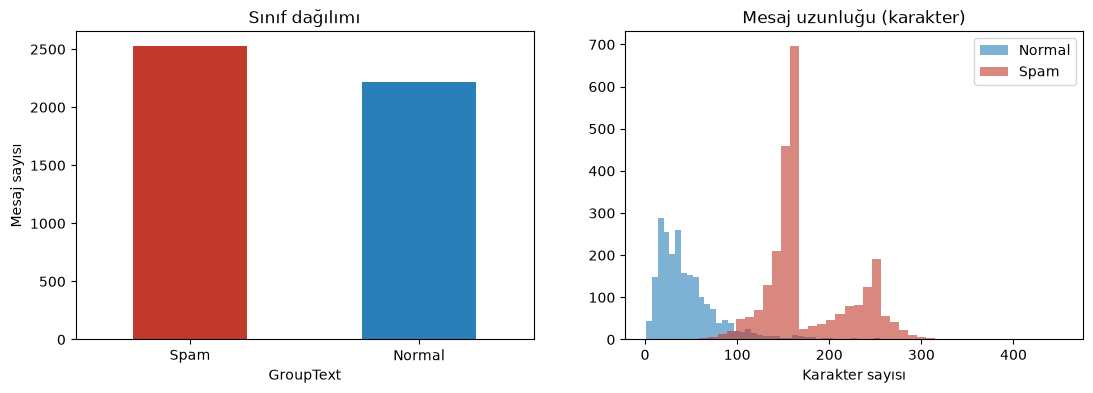

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

df["GroupText"].value_counts().plot.bar(ax=ax[0], color=["#c0392b", "#2980b9"])
ax[0].set_title("Sınıf dağılımı")
ax[0].set_ylabel("Mesaj sayısı")
ax[0].tick_params(axis="x", rotation=0)

df["karakter"] = df.Message.str.len()
for etiket, renk in [("Normal", "#2980b9"), ("Spam", "#c0392b")]:
    ax[1].hist(df[df.GroupText == etiket].karakter, bins=40, alpha=0.6, label=etiket, color=renk)
ax[1].set_title("Mesaj uzunluğu (karakter)")
ax[1].set_xlabel("Karakter sayısı")
ax[1].legend()
plt.show()

In [6]:
df.groupby("GroupText")["karakter"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
GroupText,,,,,,,,
Normal,2214.0,46.4,35.9,1.0,22.0,37.0,59.0,255.0
Spam,2526.0,176.1,46.9,59.0,150.0,159.0,214.0,453.0


Spam mesajlar belirgin şekilde daha uzun: ortalama ~176 karaktere karşılık normal mesajlarda ~46. Spam mesajlar SMS'in karakter sınırını doldurmaya çalışan reklam metinleri, normal mesajlar ise kısa günlük konuşmalar.

In [7]:
print("--- Örnek SPAM mesajlar ---")
for m in df[df.label == 1].Message.sample(4, random_state=1):
    print("*", m)
print("\n--- Örnek NORMAL mesajlar ---")
for m in df[df.label == 0].Message.sample(4, random_state=1):
    print("*", m)

--- Örnek SPAM mesajlar ---
* Bayramda Paylasmak Guzeldir! Altinyildiz Classics'te Bayram alisverisine,ikinci bir kisi ile gelin,Takim Elbise+Gomlek+Kravat setine 299TL odeyin.(2'li alimda gecerlidir).Ustelik Yazlik urunlerde %70 SON INDIRIM.
* Hizli ve rahat! Slazenger unisex kosu ayakkabisi %50 indirimle sadece 79 TL! Ucretsiz Kargo avantaji ile kacirmayin: n11.com/Slazenger
* Faturanizi kontrol altinda tutmak sizin elinizde. FaturaTakip ile kesilmis fatura tutariniz, 10. ve 20. gunde harcama tutariniz cebinize gelecek. Ustelik dilediginiz zaman dilediginiz kadar harcamalarinizi sorgulayabileceksiniz. Hemen 2222e FATURATAKIP yazip gonderin.
* Diger bankadaki ihtiyac kredinizi Akbank'a tasiyin %0,99 faizli masrafsiz krediyi kacirmayin! 10bin TL 36 ayda sigorta dahil maliyet aylik %1,26 yillik %15,16

--- Örnek NORMAL mesajlar ---
* Eee babam ne dedi
* Rahatsız olunacak ne var gerçekten anlayamıyorum çünkü :(
* Niye bana haber vermedin benim evim var burada
* Şimdi karara varalım


## 2. Türkçe metin temizleme ve tokenization (Ders 1)

LAB1'deki `clean_text` fonksiyonunu temel aldım, SMS'e özgü birkaç adım ekledim:

* **Türkçe büyük/küçük harf:** Python'un `lower()` fonksiyonu `I → i` ve `İ → i̇` yapıyor, Türkçe için yanlış. Önce `I → ı`, `İ → i` dönüşümü yapılıyor.
* **Özel token'lar:** Spam mesajlarda link, telefon numarası ve fiyat gibi bilgiler var. Bunların her biri farklı bir kelime gibi sayılırsa model genelleme yapamaz. O yüzden hepsini ortak bir token'a çeviriyorum: `<url>`, `<tel>`, `<para>`, `<sayi>`.
* **Tekrarlanan harfler:** `çoooook → çook` (LAB1'deki gibi en fazla 2 tekrar).
* Noktalama işaretleri siliniyor.

In [8]:
def turkce_kucuk(text):
    return text.replace("I", "ı").replace("İ", "i").lower()


def temizle(text, ozel_token=True):
    text = turkce_kucuk(text)
    if ozel_token:
        text = re.sub(r"(https?://\S+|www\.\S+|\b[\w-]+\.(com|net|org|im|ly|co|tr)(/\S*)?)", " <url> ", text)
        text = re.sub(r"(\+?9?0?[\s-]?\(?\d{3}\)?[\s-]?\d{3}[\s-]?\d{2}[\s-]?\d{2})", " <tel> ", text)
        text = re.sub(r"\d+[.,]?\d*\s?(tl|lira|₺)", " <para> ", text)
        text = re.sub(r"\d+", " <sayi> ", text)
    text = re.sub(r"(.)\1+", r"\1\1", text)                   # çoooook -> çook
    noktalama = string.punctuation.replace("<", "").replace(">", "")
    text = text.translate(str.maketrans(noktalama, " " * len(noktalama)))
    return " ".join(text.split())


ornekler = [
    "DIGITURKTEN FIRSAT! AYDA SADECE 10 TL.HEMEN ARAYIN 02122129070",
    "BiP ile mesajlarimi aninda gonderiyorum! http://mobiltr.co/BiP",
    "İyiyim teşekkürler, sen nasılsın :) çoooook özledim",
]
for o in ornekler:
    print(o, "\n  ->", temizle(o), "\n")

DIGITURKTEN FIRSAT! AYDA SADECE 10 TL.HEMEN ARAYIN 02122129070 
  -> dıgıturkten fırsat ayda sadece <para> hemen arayın <tel> <sayi> 

BiP ile mesajlarimi aninda gonderiyorum! http://mobiltr.co/BiP 
  -> bip ile mesajlarimi aninda gonderiyorum <url> 

İyiyim teşekkürler, sen nasılsın :) çoooook özledim 
  -> iyiyim teşekkürler sen nasılsın çook özledim 



In [9]:
df["temiz"] = df.Message.apply(temizle)
df["tokenler"] = df.temiz.str.split()
df[["Message", "temiz", "GroupText"]].sample(5, random_state=3)

,Message,temiz,GroupText
1196,CNS AVM 'de Tüm Çocuk ürünleri - Quıksılver ürünler % 50 İNDİRİMLİİİ... Keyifli Alışverişler.SMS almak istemiyorsanı...,cns avm de tüm çocuk ürünleri quıksılver ürünler <sayi> indirimlii keyifli alışverişler sms almak istemiyorsanız <ur...,Spam
2395,"Kampanya,VakifBank Worldcardla 31 Ocaka kadar ATM,4440724,Internet Bankaciliginda aylik 148TL taksitle 1200TL,366TL ...",kampanya vakifbank worldcardla <sayi> ocaka kadar atm <sayi> ınternet bankaciliginda aylik <para> taksitle <para> <p...,Spam
1041,BU FIYATLAR BAYRAMDAN BAYRAMA 1AL 1BEDAVA 2 ADT ALTNYLDZ T.ELBISE 299TL 2 ADT HAKIKI DERI AYAKKABI 99TL TRIKO 15 MON...,bu fıyatlar bayramdan bayrama <sayi> al <sayi> bedava <sayi> adt altnyldz t elbıse <para> <sayi> adt hakıkı derı aya...,Spam
1757,"Gelecek hayallerinizi ertelemeyin. %25 Devlet Katkisi, Yasam Kulupleri uyeligi ve World Puan firsatlariyla dolu Bire...",gelecek hayallerinizi ertelemeyin <sayi> devlet katkisi yasam kulupleri uyeligi ve world puan firsatlariyla dolu bir...,Spam
2040,Hmmm ben almiyim o zaman. Bi de lastik falan yarmayalim durduk yere??,hmm ben almiyim o zaman bi de lastik falan yarmayalim durduk yere,Normal


### En sık kelimeler

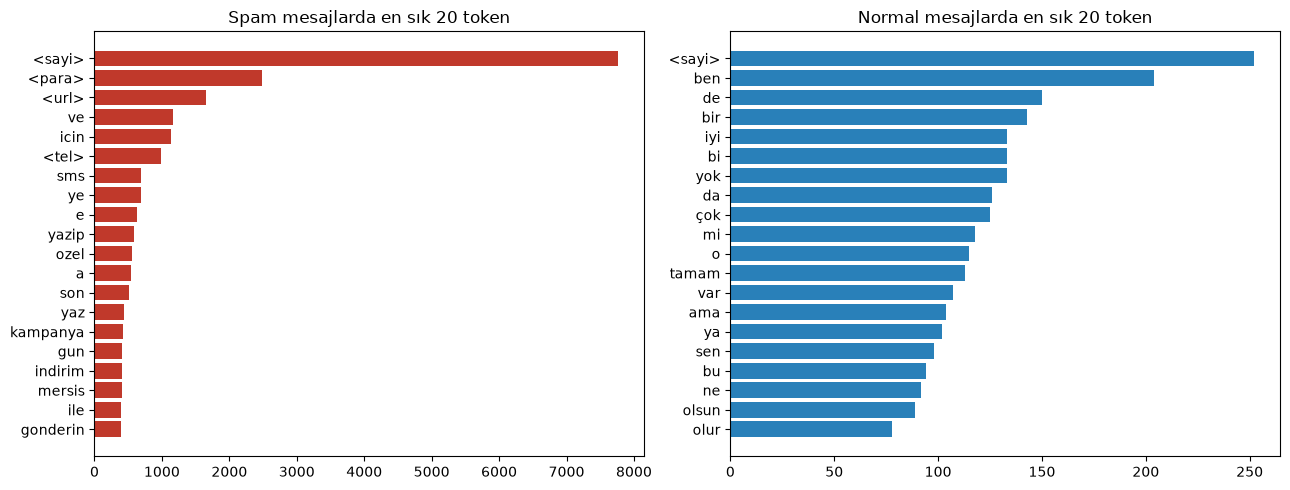

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for i, (etiket, renk) in enumerate([(1, "#c0392b"), (0, "#2980b9")]):
    sayac = Counter(t for tokenler in df[df.label == etiket].tokenler for t in tokenler)
    en_sik = sayac.most_common(20)[::-1]
    ax[i].barh([k for k, _ in en_sik], [v for _, v in en_sik], color=renk)
    ax[i].set_title(("Spam" if etiket else "Normal") + " mesajlarda en sık 20 token")
plt.tight_layout()
plt.show()

Spam mesajlarda `<sayi>`, `<url>`, `<para>`, `<tel>` token'ları ve *için, yaz, gönder, sms, kampanya, indirim* gibi kelimeler öne çıkıyor. Normal mesajlarda ise *ben, ne, sen, bir, mi, abi* gibi günlük konuşma kelimeleri var. Özel token'lar spam'in en güçlü işaretlerinden.

## 3. Eğitim / test ayrımı

Verinin %80'i eğitim, %20'si test için ayrılıyor. `stratify` ile iki kümede de spam/normal oranı aynı tutuluyor. Tüm modeller **aynı** ayrımla değerlendiriliyor.

In [11]:
idx_train, idx_test = train_test_split(
    df.index.to_numpy(), test_size=0.2, random_state=RANDOM_STATE, stratify=df.label)

X_train, X_test = df.temiz[idx_train].to_numpy(), df.temiz[idx_test].to_numpy()
y_train, y_test = df.label[idx_train].to_numpy(), df.label[idx_test].to_numpy()

print("Eğitim:", len(X_train), "  Test:", len(X_test))
print("Eğitimde spam oranı: %.3f   Testte spam oranı: %.3f" % (y_train.mean(), y_test.mean()))

Eğitim: 3792   Test: 948
Eğitimde spam oranı: 0.533   Testte spam oranı: 0.533


## 4. Sıfırdan Bayes sınıflandırıcı: Markov dil modeli (Ders 4–5)

Derste (`toy_bayes.ipynb`, LAB4) her sınıf için ayrı bir **1. derece Markov dil modeli** $M = \{\pi, A_1\}$ kurup Bayes teoremiyle sınıflandırma yaptık:

$$P(M_c \mid S) \propto P(S \mid M_c)\, P(M_c)$$

$$\log P(S \mid M_c) = \log \pi_c(s_1) + \sum_{i=2}^{n} \log A_c(s_i \mid s_{i-1})$$

Burada aynı yöntemi kütüphane kullanmadan spam/normal için yazıyorum. İki iyileştirme var:
* **Log olasılık:** Uzun mesajlarda olasılıkların çarpımı sıfıra yaklaşıp taşma (underflow) yapıyor. Bu yüzden çarpım yerine log'ların toplamı kullanılıyor (Ders 5'teki formül).
* **Add-one (Laplace) yumuşatma:** `toy_bayes`'teki gibi sayımlar 1'den başlıyor. Eğitimde hiç görülmemiş bir kelime geçişi olasılığı sıfırlamasın diye.
* **`<unk>` token'ının öğrenilmesi:** `toy_bayes`'te bilinmeyen kelimeler `<unk>`'ya çevriliyordu, ama eğitimde hiç `<unk>` görülmediği için bu token'ın iki sınıfta da olasılığı aynıydı. Burada eğitimde **sadece 1 kez geçen kelimeleri de `<unk>` yapıyorum**. Böylece model "bu sınıfta nadir/bilinmeyen kelime ne sıklıkta çıkıyor" bilgisini de öğreniyor. Bunun neden önemli olduğu aşağıda deneyle gösteriliyor.

In [12]:
class MarkovBayes:
    """Her sınıf için 1. derece Markov dil modeli + Bayes kuralı."""

    def __init__(self, min_count=2):
        self.min_count = min_count   # eğitimde bundan az geçen kelimeler <unk> sayılır

    def fit(self, X, y):
        sayac = Counter(t for doc in X for t in doc.split())
        self.w2i = {"<unk>": 0}
        for doc in X:
            for t in doc.split():
                if t not in self.w2i and sayac[t] >= self.min_count:
                    self.w2i[t] = len(self.w2i)
        V = len(self.w2i)
        self.siniflar = sorted(set(y))
        self.log_pi, self.log_A, self.log_prior = {}, {}, {}
        for c in self.siniflar:
            docs = [d for d, l in zip(X, y) if l == c]
            pi = np.ones(V)                       # add-one yumuşatma
            A = {}                                # seyrek geçiş sayıları: (önceki, şimdiki) -> sayı
            satir_toplam = np.full(V, V, dtype=float)
            for d in docs:
                idx = [self.w2i.get(t, 0) for t in d.split()]
                if not idx:
                    continue
                pi[idx[0]] += 1
                for p, s in zip(idx[:-1], idx[1:]):
                    A[(p, s)] = A.get((p, s), 0) + 1
                    satir_toplam[p] += 1
            self.log_pi[c] = np.log(pi / pi.sum())
            self.log_A[c] = (A, np.log(satir_toplam))
            self.log_prior[c] = np.log(len(docs) / len(X))
        return self

    def log_likelihood(self, doc, c):
        idx = [self.w2i.get(t, 0) for t in doc.split()]
        if not idx:
            return 0.0
        A, log_satir = self.log_A[c]
        toplam = self.log_pi[c][idx[0]]
        for p, s in zip(idx[:-1], idx[1:]):
            toplam += np.log(A.get((p, s), 0) + 1) - log_satir[p]
        return toplam

    def predict(self, X, prior_kullan=True):
        tahminler = []
        for doc in X:
            skorlar = {c: self.log_likelihood(doc, c) + (self.log_prior[c] if prior_kullan else 0)
                       for c in self.siniflar}
            tahminler.append(max(skorlar, key=skorlar.get))
        return np.array(tahminler)


markov_bayes = MarkovBayes().fit(X_train, y_train)
print("Sözlük büyüklüğü:", len(markov_bayes.w2i))
print("Prior'lar:", {int(c): round(float(np.exp(v)), 3) for c, v in markov_bayes.log_prior.items()})

Sözlük büyüklüğü: 4249
Prior'lar: {0: 0.467, 1: 0.533}


In [13]:
def degerlendir(y_true, y_pred, isim):
    return {
        "Model": isim,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (spam)": precision_score(y_true, y_pred, zero_division=0),
        "Recall (spam)": recall_score(y_true, y_pred, zero_division=0),
        "F1 (spam)": f1_score(y_true, y_pred, zero_division=0),
    }


tahmin_markov = markov_bayes.predict(X_test)
sonuclar = [degerlendir(y_test, tahmin_markov, "Markov-Bayes (sıfırdan)")]
pd.DataFrame(sonuclar).round(4)

,Model,Accuracy,Precision (spam),Recall (spam),F1 (spam)
0,Markov-Bayes (sıfırdan),0.9673,0.9422,1.0,0.9702


### `<unk>` eşiğinin etkisi
`min_count=1` toy_bayes'teki duruma karşılık geliyor: Eğitimde görülen her kelime sözlüğe giriyor, `<unk>` hiç öğrenilmiyor.

In [14]:
unk_deney = []
for mc in [1, 2, 3]:
    tahmin = MarkovBayes(min_count=mc).fit(X_train, y_train).predict(X_test)
    unk_deney.append(degerlendir(y_test, tahmin, f"Markov-Bayes (min_count={mc})"))
pd.DataFrame(unk_deney).set_index("Model").round(4)

,Accuracy,Precision (spam),Recall (spam),F1 (spam)
Model,,,,
Markov-Bayes (min_count=1),0.8703,0.8041,1.0,0.8914
Markov-Bayes (min_count=2),0.9673,0.9422,1.0,0.9702
Markov-Bayes (min_count=3),0.9736,0.9528,1.0,0.9758


`min_count=1` iken model, normal mesajlardaki **bilinmeyen kelimelerden** oluşan kısa mesajları ("Geliom", "Annemdeyiz" gibi) spam sanıyor. Bilinmeyen kelime iki sınıfta da aynı olasılığı aldığı için karar sadece prior'a kalıyor, spam prior'ı biraz daha büyük olduğu için de sonuç spam çıkıyor. Oysa günlük konuşma dilinde (yazım hataları, ağız, kısaltmalar) nadir kelime çok daha sık. `<unk>` öğretildiğinde model bunu fark ediyor ve F1 belirgin şekilde artıyor. Ana model olarak standart değer olan `min_count=2` kullanılıyor.

Aşağıda modelin kararını nasıl verdiğini tek tek mesajlar üzerinde görüyoruz:

In [15]:
for mesaj in ["Kampanya! Tüm ürünlerde %50 indirim, hemen tıkla", "abi akşam maça geliyor musun", "Tebrikler 1000 TL kazandınız, kazancinizi almak icin 3434'e SMS gonderin"]:
    t = temizle(mesaj)
    ll = {c: markov_bayes.log_likelihood(t, c) + markov_bayes.log_prior[c] for c in (0, 1)}
    print(f"{mesaj}\n   log P(normal|S) ∝ {ll[0]:.1f}   log P(spam|S) ∝ {ll[1]:.1f}   ->  {'SPAM' if ll[1] > ll[0] else 'NORMAL'}\n")

Kampanya! Tüm ürünlerde %50 indirim, hemen tıkla
   log P(normal|S) ∝ -58.9   log P(spam|S) ∝ -43.2   ->  SPAM

abi akşam maça geliyor musun
   log P(normal|S) ∝ -38.3   log P(spam|S) ∝ -42.8   ->  NORMAL

Tebrikler 1000 TL kazandınız, kazancinizi almak icin 3434'e SMS gonderin
   log P(normal|S) ∝ -83.8   log P(spam|S) ∝ -65.2   ->  SPAM



## 5. Multinomial Naive Bayes: Count ve TF-IDF (Ders 2–3, LAB5)

Şimdi kelime sırasını dikkate almayan **bag-of-words** yaklaşımı: mesajlar sayma vektörlerine (`CountVectorizer`) ya da TF-IDF vektörlerine (`TfidfVectorizer`) çevrilip scikit-learn'ün `MultinomialNB` modeline veriliyor. Tek kelimelerin yanında ikili kelime gruplarını (bigram, `ngram_range=(1, 2)`) eklemenin etkisine de bakıyorum.

In [16]:
deneyler = {
    "MNB + Count (unigram)": CountVectorizer(token_pattern=r"\S+"),
    "MNB + Count (uni+bigram)": CountVectorizer(token_pattern=r"\S+", ngram_range=(1, 2)),
    "MNB + TF-IDF (unigram)": TfidfVectorizer(token_pattern=r"\S+"),
    "MNB + TF-IDF (uni+bigram)": TfidfVectorizer(token_pattern=r"\S+", ngram_range=(1, 2)),
}

modeller = {}
for isim, vectorizer in deneyler.items():
    Xtr = vectorizer.fit_transform(X_train)
    Xte = vectorizer.transform(X_test)
    model = MultinomialNB().fit(Xtr, y_train)
    modeller[isim] = (vectorizer, model)
    sonuclar.append(degerlendir(y_test, model.predict(Xte), isim))
    print(f"{isim:28s} sözlük boyutu: {len(vectorizer.vocabulary_)}")

sonuc_df = pd.DataFrame(sonuclar).set_index("Model").round(4)
sonuc_df

MNB + Count (unigram)        sözlük boyutu: 10591
MNB + Count (uni+bigram)     sözlük boyutu: 39018
MNB + TF-IDF (unigram)       sözlük boyutu: 10591
MNB + TF-IDF (uni+bigram)    sözlük boyutu: 39018


,Accuracy,Precision (spam),Recall (spam),F1 (spam)
Model,,,,
Markov-Bayes (sıfırdan),0.9673,0.9422,1.0,0.9702
MNB + Count (unigram),0.9810,0.9656,1.0,0.9825
MNB + Count (uni+bigram),0.9705,0.9475,1.0,0.9730
MNB + TF-IDF (unigram),0.9747,0.9546,1.0,0.9768
MNB + TF-IDF (uni+bigram),0.9652,0.9387,1.0,0.9684


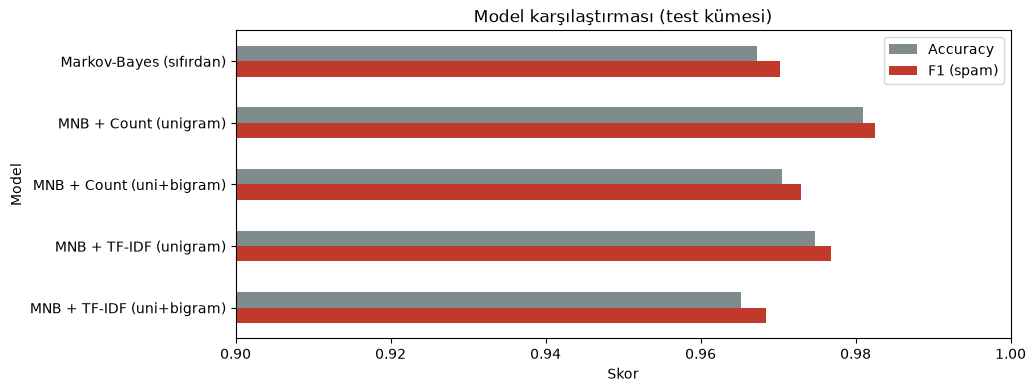

In [17]:
sonuc_df[["Accuracy", "F1 (spam)"]].plot.barh(figsize=(10, 4), xlim=(0.9, 1.0), color=["#7f8c8d", "#c0392b"])
plt.title("Model karşılaştırması (test kümesi)")
plt.xlabel("Skor")
plt.gca().invert_yaxis()
plt.show()

### Özel token'ların etkisi (ablation)
Temizlemede link/telefon/para/sayı yerine özel token koymak gerçekten işe yarıyor mu? Aynı modeli, aynı eğitim/test ayrımıyla özel token'lar olmadan eğitip karşılaştırıyorum.

In [18]:
df["temiz_tokensiz"] = df.Message.apply(lambda m: temizle(m, ozel_token=False))
# aynı eğitim/test ayrımı (idx_train, idx_test) kullanılıyor
Xtr_raw, Xte_raw = df.temiz_tokensiz[idx_train].to_numpy(), df.temiz_tokensiz[idx_test].to_numpy()
ytr_raw, yte_raw = y_train, y_test

ablation = []
for ad, (Xa, Xb, ya, yb) in {"Özel token'lı": (X_train, X_test, y_train, y_test),
                              "Özel token'sız": (Xtr_raw, Xte_raw, ytr_raw, yte_raw)}.items():
    v = CountVectorizer(token_pattern=r"\S+")
    m = MultinomialNB().fit(v.fit_transform(Xa), ya)
    r = degerlendir(yb, m.predict(v.transform(Xb)), ad)
    r["Sözlük boyutu"] = len(v.vocabulary_)
    ablation.append(r)
pd.DataFrame(ablation).set_index("Model").round(4)

,Accuracy,Precision (spam),Recall (spam),F1 (spam),Sözlük boyutu
Model,,,,,
Özel token'lı,0.981,0.9656,1.0,0.9825,10591
Özel token'sız,0.981,0.9656,1.0,0.9825,12467


İlginç bir sonuç: Özel token'lar bu veri setinde **başarıyı değiştirmiyor**, ama sözlüğü yaklaşık %15 küçültüyor. Spam mesajlar zaten *kampanya, indirim, gönder, sms* gibi kelimelerle o kadar belirgin ki tek tek numaralara ihtiyaç kalmıyor. Yine de özel token'lar modeli daha küçük ve genellenebilir yapıyor: Eğitimde hiç görülmemiş yeni bir telefon numarası ya da link de `<tel>` / `<url>` olarak tanınıyor.

### Hangi kelimeler spam'i ele veriyor?
Naive Bayes'te her kelimenin sınıflara göre log olasılığı var. `log P(kelime | spam) − log P(kelime | normal)` farkı en büyük kelimeler spam'in, en küçük kelimeler normal mesajın en güçlü işaretleri.

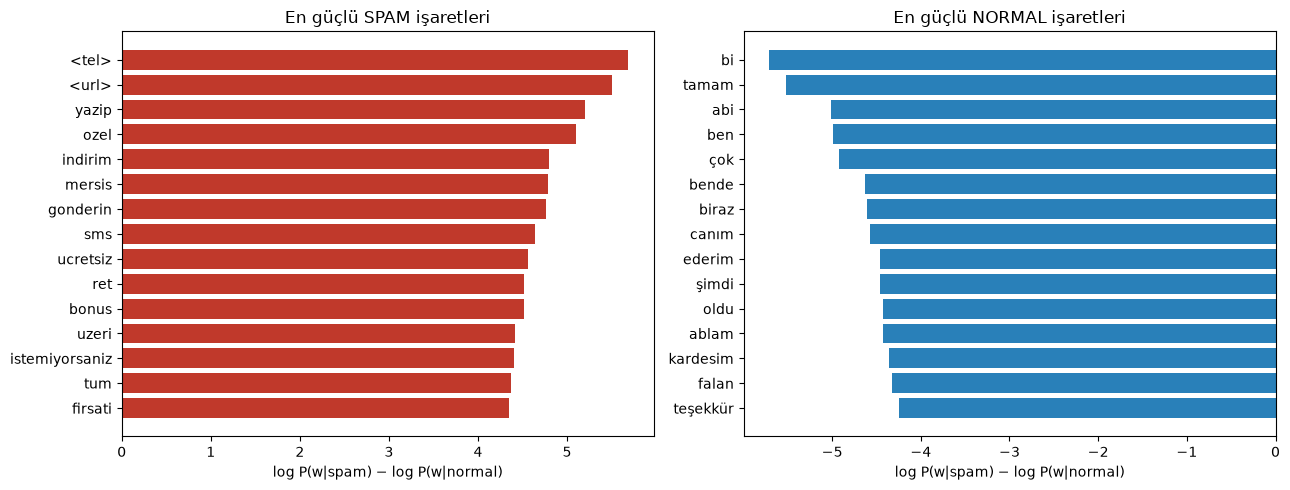

In [19]:
vec, mnb = modeller["MNB + Count (unigram)"]
kelimeler = vec.get_feature_names_out()
fark = mnb.feature_log_prob_[1] - mnb.feature_log_prob_[0]
sirali = np.argsort(fark)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].barh(kelimeler[sirali[-15:]], fark[sirali[-15:]], color="#c0392b")
ax[0].set_title("En güçlü SPAM işaretleri")
ax[1].barh(kelimeler[sirali[:15]][::-1], fark[sirali[:15]][::-1], color="#2980b9")
ax[1].set_title("En güçlü NORMAL işaretleri")
for a in ax:
    a.set_xlabel("log P(w|spam) − log P(w|normal)")
plt.tight_layout()
plt.show()

En yüksek F1: MNB + Count (unigram)


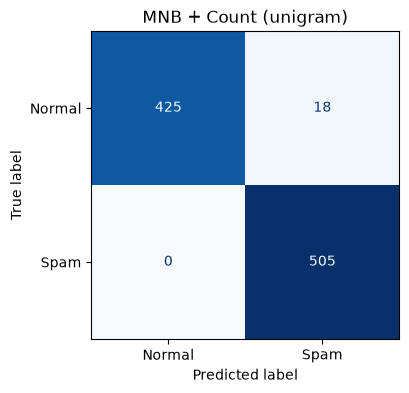

In [20]:
en_iyi = sonuc_df["F1 (spam)"].idxmax()
print("En yüksek F1:", en_iyi)
if en_iyi.startswith("Markov"):
    tahmin_en_iyi = tahmin_markov
else:
    v, m = modeller[en_iyi]
    tahmin_en_iyi = m.predict(v.transform(X_test))

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, tahmin_en_iyi),
                       display_labels=["Normal", "Spam"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(en_iyi)
plt.show()

### Hata analizi
Modelin yanlış sınıflandırdığı mesajlara bakmak, modelin neyi öğrenemediğini gösteriyor.

In [21]:
hatalar = pd.DataFrame({"Mesaj": df.Message[idx_test].values,
                        "Gerçek": np.where(y_test == 1, "Spam", "Normal"),
                        "Tahmin": np.where(tahmin_en_iyi == 1, "Spam", "Normal")})
hatalar = hatalar[hatalar.Gerçek != hatalar.Tahmin]
print("Toplam hata:", len(hatalar), "/", len(y_test))
hatalar

Toplam hata: 18 / 948


,Mesaj,Gerçek,Tahmin
76,Facebooookkkk :)),Normal,Spam
112,SAYGILAR,Normal,Spam
309,.,Normal,Spam
437,Genel merkezden cep telefonumdan aradılar,Normal,Spam
438,7. sırada,Normal,Spam
543,Hemen döndüm,Normal,Spam
585,Anaaaam bu kırkınıda beklemicek,Normal,Spam
632,Annemdeyiz,Normal,Spam
665,Cep mesgul,Normal,Spam
685,Sobiad Atıf dizini,Normal,Spam


Hataların **hepsi** aynı türden: Kısa normal mesajlar spam sanılıyor, gerçek spam'lerin hiçbiri kaçmıyor (recall = 1.0). Bu mesajların çoğu ("Geliom", "Annemdeyiz", "SAYGILAR", ".") ya eğitimde hiç görülmemiş kelimelerden oluşuyor ya da hiç kelime içermiyor. Bu durumda mesajın vektörü tamamen sıfır oluyor ve Naive Bayes sadece prior'a bakıyor. Eğitimde spam biraz daha fazla olduğu için de karar spam çıkıyor. Bölüm 4'teki Markov-Bayes modelinde `<unk>` öğretilerek bu sorun azaltılmıştı. Bag-of-words modellerinde de benzer bir çözüm uygulanabilir.

## 6. Dengesiz veri senaryosu (Ders 6)

Bu veri setinde spam ve normal mesaj sayıları birbirine yakın. **Gerçek hayatta ise** gelen SMS'lerin çok küçük bir kısmı spam. Ders 6'daki örnekte olduğu gibi ({900 Türkçe, 100 İngilizce}), dengesiz veride **accuracy yanıltıcıdır**.

Bunu göstermek için gerçekçi bir senaryo kuruyorum: Spam mesajların bir kısmını atıp **spam oranını %10'a** düşürüyorum, sonra şunları karşılaştırıyorum:
1. **"Her şeye normal de" modeli:** hiçbir şey öğrenmeyen, her mesaja *normal* diyen bir model
2. Naive Bayes ve Markov-Bayes modelleri

Bakılacak metrikler Ders 6'dakiler: confusion matrix, precision, recall, F1.

In [22]:
normal = df[df.label == 0]
spam = df[df.label == 1]
spam_sayisi = int(len(normal) * 0.10 / 0.90)       # spam oranı %10 olacak şekilde
dengesiz = pd.concat([normal, spam.sample(spam_sayisi, random_state=RANDOM_STATE)])

print("Normal:", len(normal), " Spam:", spam_sayisi, f" Spam oranı: {spam_sayisi / len(dengesiz):.3f}")

Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    dengesiz.temiz.to_numpy(), dengesiz.label.to_numpy(),
    test_size=0.2, random_state=RANDOM_STATE, stratify=dengesiz.label)
print("Testteki spam sayısı:", yd_test.sum(), "/", len(yd_test))

Normal: 2214  Spam: 246  Spam oranı: 0.100
Testteki spam sayısı: 49 / 492


In [23]:
dengesiz_sonuclar = []

# 1) Her şeye "normal" diyen model
dengesiz_sonuclar.append(degerlendir(yd_test, np.zeros_like(yd_test), "Her şeye 'normal' de"))

# 2) Naive Bayes (Count)
v = CountVectorizer(token_pattern=r"\S+")
mnb_d = MultinomialNB().fit(v.fit_transform(Xd_train), yd_train)
tahmin_mnb_d = mnb_d.predict(v.transform(Xd_test))
dengesiz_sonuclar.append(degerlendir(yd_test, tahmin_mnb_d, "MNB + Count"))

# 3) Markov-Bayes: prior'lı ve prior'sız
mb_d = MarkovBayes().fit(Xd_train, yd_train)
tahmin_mb_d = mb_d.predict(Xd_test)
dengesiz_sonuclar.append(degerlendir(yd_test, tahmin_mb_d, "Markov-Bayes (prior'lı)"))
dengesiz_sonuclar.append(degerlendir(yd_test, mb_d.predict(Xd_test, prior_kullan=False), "Markov-Bayes (prior'sız)"))

pd.DataFrame(dengesiz_sonuclar).set_index("Model").round(4)

,Accuracy,Precision (spam),Recall (spam),F1 (spam)
Model,,,,
Her şeye 'normal' de,0.9004,0.0000,0.0000,0.0000
MNB + Count,0.9959,0.9796,0.9796,0.9796
Markov-Bayes (prior'lı),0.9878,1.0000,0.8776,0.9348
Markov-Bayes (prior'sız),0.9736,0.8462,0.8980,0.8713


Markov-Bayes'in **prior'lı ve prior'sız** sonuçları Bayes teoreminde prior'ın rolünü gösteriyor. Prior kullanılmadığında model iki sınıfı eşit olası sayıyor. Biraz daha fazla spam yakalıyor (recall biraz daha yüksek), ama bu sefer normal mesajları da spam sanmaya başlıyor (precision düşüyor). Prior, gerçekte spam'in nadir olduğu bilgisini modele katıyor. Precision'ı belirgin şekilde yükseltiyor, karşılığında birkaç spam kaçıyor. Spam filtresinde normal mesajı kaybetmek daha kötü olduğu için bu iyi bir takas.

**Sonuç:** Hiçbir şey öğrenmeyen *"her şeye normal de"* modeli bile **%90 accuracy** alıyor, ama tek bir spam'i bile yakalamıyor (recall = 0, F1 = 0). Dengesiz veride accuracy'ye bakıp "model başarılı" demek yanlış. Asıl ölçü spam sınıfı için **precision, recall ve F1**.

Spam filtresinde iki hata türünün maliyeti farklı:
* **False positive** (normal mesajı spam sanmak): Önemli bir mesaj kaybolur, daha kötü hata.
* **False negative** (spam'i kaçırmak): Kullanıcı bir reklam görür, daha az zararlı.

Bu yüzden spam filtresinde **precision** özellikle önemli.

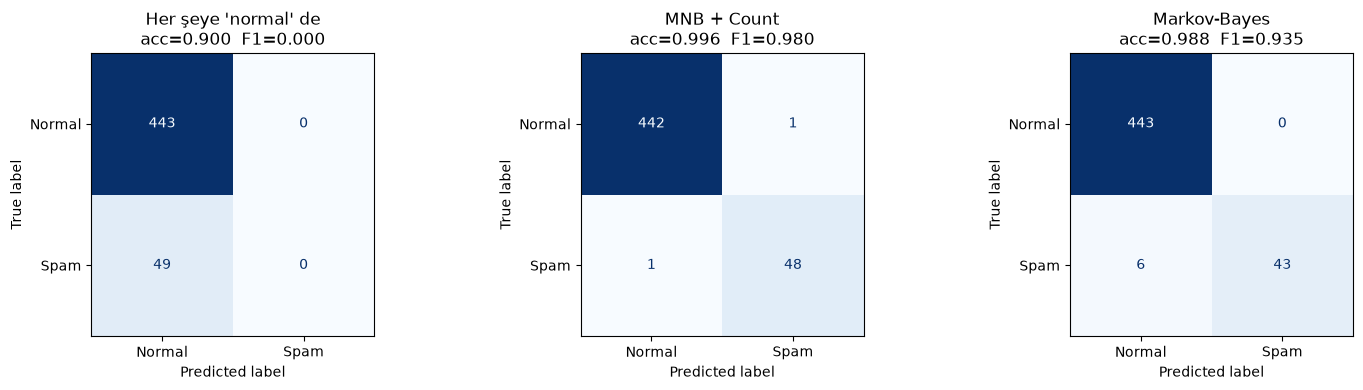

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (tahmin, baslik) in zip(ax, [(np.zeros_like(yd_test), "Her şeye 'normal' de"),
                                     (tahmin_mnb_d, "MNB + Count"),
                                     (tahmin_mb_d, "Markov-Bayes")]):
    ConfusionMatrixDisplay(confusion_matrix(yd_test, tahmin, labels=[0, 1]),
                           display_labels=["Normal", "Spam"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(f"{baslik}\nacc={accuracy_score(yd_test, tahmin):.3f}  F1={f1_score(yd_test, tahmin, zero_division=0):.3f}")
plt.tight_layout()
plt.show()

## 7. Kosinüs benzerliği ile benzer mesajları bulma (Docsim)

Docsim labındaki gibi her mesajı bir vektör olarak düşünüp **kosinüs benzerliği** hesaplıyorum:

$$\cos(\vec{u}, \vec{v}) = \frac{\vec{u} \cdot \vec{v}}{\lVert \vec{u} \rVert \, \lVert \vec{v} \rVert}$$

Spam'de bunun pratik bir kullanımı var: aynı **spam kampanyasının** küçük farklarla (numara, tarih, fiyat değişerek) tekrar tekrar gönderilen kopyalarını bulmak. Burada TF-IDF vektörleri kullanılıyor ve kosinüs benzerliği Docsim'deki gibi elle yazılıyor.

In [25]:
def cos_sim(v1, v2):
    pay = np.dot(v1, v2)
    payda = np.linalg.norm(v1) * np.linalg.norm(v2)
    return pay / payda if payda else 0.0


tfidf_tum = TfidfVectorizer(token_pattern=r"\S+")
doc_mat = tfidf_tum.fit_transform(df.temiz).toarray()


def benzerlerini_bul(mesaj, k=3):
    sorgu = tfidf_tum.transform([temizle(mesaj)]).toarray()[0]
    benzerlikler = np.array([cos_sim(sorgu, v) for v in doc_mat])
    print("SORGU:", mesaj, "\n")
    for i in (-benzerlikler).argsort()[:k]:
        print(f"  [{benzerlikler[i]:.3f}] ({df.GroupText[i]}) {df.Message[i][:140]}")
    print()


benzerlerini_bul("Turkcell'den size ozel kampanya! Ayda sadece 29 TL'ye 5 GB internet")
benzerlerini_bul("akşam yemeğe geliyor musunuz")

SORGU: Turkcell'den size ozel kampanya! Ayda sadece 29 TL'ye 5 GB internet 

  [0.428] (Spam) Turkcell Hazirkart kalitesiyle 1GB internet, heryone 500dk ve 1000 sms ayda sadece 19TL! Size ozel bu teklifimiz hakkinda detayli bilgi icin
  [0.370] (Spam) Geceleri 1GB internet sadece 5TL! Turkcell kalitesiyle 1 ay boyunca 00:00-06:00 saatleri arasi internetin keyfini cikarmak icin hemen GECE 1
  [0.345] (Spam) 5GB interneti ile film keyfi her an cebinizde! Turkcell TV+ ile 100e yakin TV kanali, ucretsiz filmler 5 GB interneti ile ayda sadece 9,90TL

SORGU: akşam yemeğe geliyor musunuz 

  [0.282] (Normal) Akşam elimde
  [0.265] (Normal) Ses geliyor mu?? 
  [0.261] (Normal) Akşam ne yapıyoruz?



In [26]:
# Spam kampanyaları: birbirine çok benzeyen (cos > 0.8) spam mesaj çiftleri
spam_idx = df.index[df.label == 1].to_numpy()
S = doc_mat[spam_idx]
S_norm = S / np.linalg.norm(S, axis=1, keepdims=True)
benzerlik_mat = S_norm @ S_norm.T
np.fill_diagonal(benzerlik_mat, 0)

esik = 0.8
kopyasi_olan = (benzerlik_mat > esik).any(axis=1)
print(f"Kendisine çok benzeyen (cos > {esik}) en az bir başka spam mesaj bulunan spam oranı: {kopyasi_olan.mean():.3f}")

i, j = np.unravel_index(np.argmax(np.where(benzerlik_mat < 0.999, benzerlik_mat, 0)), benzerlik_mat.shape)
print(f"\nBirbirine en çok benzeyen (ama aynı olmayan) iki spam, cos = {benzerlik_mat[i, j]:.3f}:")
print(" 1)", df.Message[spam_idx[i]])
print(" 2)", df.Message[spam_idx[j]])

Kendisine çok benzeyen (cos > 0.8) en az bir başka spam mesaj bulunan spam oranı: 0.265

Birbirine en çok benzeyen (ama aynı olmayan) iki spam, cos = 0.999:
 1) YENI GIRISIMCILER VE MEVCUT ISLETMELER, 10 BIN TL DEN 500 BIN TL YE KADAR YARARLANABILECEGINIZ DEVLET DESTEKLERI ICIN CAGRI BIRAKIN,SIZI ARAYALIM. 08508401790
 2) YENI GIRISIMCILER VE MEVCUT ISLETMELER, 10 BIN TL DEN 500 BIN TL YE KADAR YARARLANABILECEGINIZ DEVLET DESTEKLERI ICIN CAGRI BIRAKIN,SIZI ARAYALIM.08503027950


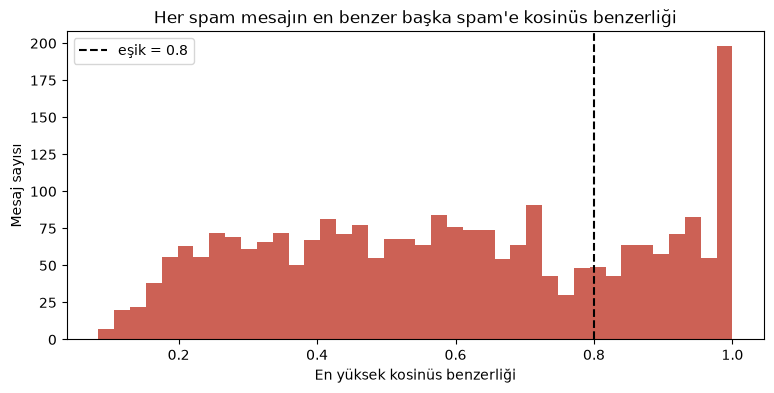

In [27]:
plt.figure(figsize=(9, 4))
plt.hist(benzerlik_mat.max(axis=1), bins=40, color="#c0392b", alpha=0.8)
plt.axvline(esik, color="black", linestyle="--", label=f"eşik = {esik}")
plt.title("Her spam mesajın en benzer başka spam'e kosinüs benzerliği")
plt.xlabel("En yüksek kosinüs benzerliği")
plt.ylabel("Mesaj sayısı")
plt.legend()
plt.show()

## 8. Markov modeliyle yapay spam üretme (Ders 4, LAB3)

LAB3'te şarkı sözleriyle eğitilen Markov modeli yeni sözler üretiyordu. Aynı yöntemi spam mesajlara uyguluyorum: $\pi$ (ilk kelime olasılıkları) ve $A_1$ (bir kelimeden sonra gelen kelimenin olasılıkları) spam mesajlardan öğrenilip yeni "spam" mesajlar üretiliyor. Mesaj sonu için `<END>` token'ı kullanılıyor.

Üretilen mesajları yukarıda eğittiğimiz sınıflandırıcıya da veriyoruz: Model, Markov'un ürettiği yapay spam'i de spam olarak tanıyor mu?

In [28]:
SON = "<END>"
pi, A1 = {}, {}
for doc in df[df.label == 1].temiz:
    tokens = doc.split()
    if not tokens:
        continue
    pi[tokens[0]] = pi.get(tokens[0], 0) + 1
    for onceki, sonraki in zip(tokens, tokens[1:] + [SON]):
        A1.setdefault(onceki, {})
        A1[onceki][sonraki] = A1[onceki].get(sonraki, 0) + 1

# frekansları olasılığa çevir (normalize)
pi_toplam = sum(pi.values())
pi = {t: s / pi_toplam for t, s in pi.items()}
for t in A1:
    toplam = sum(A1[t].values())
    A1[t] = {k: s / toplam for k, s in A1[t].items()}


def kelime_sec(d):
    rastgele = np.random.random()
    esik = 0
    for token, olasilik in d.items():
        esik += olasilik
        if esik >= rastgele:
            return token
    return token


def spam_yaz(max_uzunluk=30):
    kelimeler = [kelime_sec(pi)]
    while len(kelimeler) < max_uzunluk:
        yeni = kelime_sec(A1[kelimeler[-1]])
        if yeni == SON:
            break
        kelimeler.append(yeni)
    return " ".join(kelimeler)


np.random.seed(7)
uretilen = [spam_yaz() for _ in range(6)]
v, m = modeller["MNB + Count (unigram)"]
for s, t in zip(uretilen, m.predict(v.transform(uretilen))):
    print(f"[{'SPAM' if t else 'NORMAL'}] {s}\n")

[SPAM] <para> samsung note <sayi> prog bul mak <para> indirim <url> tr ve <sayi>

[SPAM] dıgıturkte fırsat <sayi> e gönder mersis <tel> ıletisim tercihlerinizi degistirmek icin <sayi> ekim arasinda farkli gunlerde <sayi> mk <tel> <sayi> indirim seni sasirtacak aklina takilanlari bongoya sormak icin hemen <tel>

[SPAM] ıs bankasi ndan faydalanmak icin plakasini yazin <sayi> ay lıgtv hedıye kampanyasi tum zamanlarin en heyecanlı yılbaşı ağacı seti <para> <para> ye giris yapabilirsiniz son <sayi> ekran <para> uzeri ilk

[SPAM] rengarenk havlu ve <sayi> ye gonderin mersis <tel> <sayi> daha fazlasi <url> sms gonderiniz mersis no <tel> cikmak icin vbred yazin <sayi> ve cevre temizlik vergilerinizi faizsiz ücretsiz gönder mersis

[SPAM] kredı den yari yil hediyelerinizi birlikte yasayalim unutmayin sms iptal bedeli <para> ve uzeri alisverisinize <para> ye <sayi> <sayi> marta kadar <sayi> subat

[SPAM] yılbasına ozel <para> sigorta odemelerinizde <sayi> e sms istemiyorsaniz ret yazip <sayi> k

In [29]:
np.random.seed(0)
uretilen_1000 = [spam_yaz() for _ in range(1000)]
print("Üretilen 1000 yapay spam'den spam olarak tanınanların oranı:",
      m.predict(v.transform(uretilen_1000)).mean())

Üretilen 1000 yapay spam'den spam olarak tanınanların oranı: 0.999


## 9. Kendi mesajını dene

Aşağıdaki listeye istediğin mesajı yazıp en iyi modelin ve sıfırdan yazılan Markov-Bayes modelinin tahminini görebilirsin.

In [30]:
denemeler = [
    "Merhaba, yarın sabah 9'da toplantı var unutma",
    "SON GUN! Tum urunlerde %70'e varan indirim. www.firsat.com IPTAL yaz 4444'e gonder",
    "Hocam ödevi mail attım kontrol edebilir misiniz",
    "Hediye çeki kazandınız! Hemen tıklayın bit.ly/xyz",
]
v, m = modeller["MNB + Count (unigram)"]
temiz_denemeler = [temizle(d) for d in denemeler]
for d, p_mnb, p_mb, olas in zip(denemeler,
                                m.predict(v.transform(temiz_denemeler)),
                                markov_bayes.predict(temiz_denemeler),
                                m.predict_proba(v.transform(temiz_denemeler))[:, 1]):
    print(f"MNB: {'SPAM  ' if p_mnb else 'NORMAL'} (P(spam)={olas:.2f}) | Markov-Bayes: {'SPAM  ' if p_mb else 'NORMAL'} | {d}")

MNB: NORMAL (P(spam)=0.00) | Markov-Bayes: NORMAL | Merhaba, yarın sabah 9'da toplantı var unutma
MNB: SPAM   (P(spam)=1.00) | Markov-Bayes: SPAM   | SON GUN! Tum urunlerde %70'e varan indirim. www.firsat.com IPTAL yaz 4444'e gonder
MNB: NORMAL (P(spam)=0.00) | Markov-Bayes: NORMAL | Hocam ödevi mail attım kontrol edebilir misiniz
MNB: SPAM   (P(spam)=1.00) | Markov-Bayes: SPAM   | Hediye çeki kazandınız! Hemen tıklayın bit.ly/xyz


## 10. Sonuç

In [31]:
print("Dengeli veri seti (test kümesi):")
print(sonuc_df.to_string())
print("\nDengesiz senaryo (%10 spam):")
print(pd.DataFrame(dengesiz_sonuclar).set_index("Model").round(4).to_string())

Dengeli veri seti (test kümesi):
                           Accuracy  Precision (spam)  Recall (spam)  F1 (spam)
Model                                                                          
Markov-Bayes (sıfırdan)      0.9673            0.9422            1.0     0.9702
MNB + Count (unigram)        0.9810            0.9656            1.0     0.9825
MNB + Count (uni+bigram)     0.9705            0.9475            1.0     0.9730
MNB + TF-IDF (unigram)       0.9747            0.9546            1.0     0.9768
MNB + TF-IDF (uni+bigram)    0.9652            0.9387            1.0     0.9684

Dengesiz senaryo (%10 spam):
                          Accuracy  Precision (spam)  Recall (spam)  F1 (spam)
Model                                                                         
Her şeye 'normal' de        0.9004            0.0000         0.0000     0.0000
MNB + Count                 0.9959            0.9796         0.9796     0.9796
Markov-Bayes (prior'lı)     0.9878            1.0000         

* Derste gördüğümüz basit yöntemler (sayma vektörleri, TF-IDF, Naive Bayes, Markov dil modeli) Türkçe SMS spam tespitinde çok yüksek başarı veriyor. Spam mesajların dili (kampanya, indirim, link, numara, "… yaz … gönder" kalıbı) normal konuşmadan çok farklı.
* **Kütüphanesiz yazılan Markov-Bayes** sınıflandırıcı, `<unk>` token'ı öğretildiğinde scikit-learn'ün Naive Bayes modellerine yakın sonuçlar veriyor. `<unk>` öğretilmezse kısa ve nadir kelimeli normal mesajları spam sanıyor. En iyi sonuç, en basit model olan **Count + MultinomialNB**'den geldi.
* Modellerin neredeyse tüm hataları **kısa normal mesajlar** (bilinmeyen kelimeler → sıfır vektör → karar prior'a kalıyor). Spam mesajları kaçırma neredeyse yok.
* **Özel token'lar** (`<url>`, `<tel>`, `<para>`, `<sayi>`) bu veri setinde başarıyı değiştirmedi, ama sözlüğü ~%15 küçülttü ve yeni numaraları/linkleri tanınabilir hale getirdi.
* **Dengesiz veri** senaryosu, accuracy'nin tek başına yanıltıcı olduğunu net gösteriyor: Hiçbir şey öğrenmeyen model bile %90 accuracy alıyor. Bu yüzden precision, recall ve F1'e bakmak gerekiyor.
* **Kosinüs benzerliği** ile spam mesajların yaklaşık dörtte birinin, aynı kampanyanın küçük farklarla (numara, tarih, fiyat) tekrar gönderilmiş kopyaları olduğu görülüyor.

**Sınırlılıklar ve geliştirme fikirleri:** Veri seti birkaç bin mesajlık ve belli bir dönemden. Yeni tip spam'ler (ör. kargo/banka dolandırıcılığı) farklı bir dil kullanabilir. Veri setindeki spam'lerin çoğu Türkçe karakter kullanmıyor ("DIGITURK" → "dıgıturk" gibi), bu da Türkçe küçük harf dönüşümünde bazı bozulmalara yol açıyor. Kök bulma (stemming), karar ağaçları ve çapraz doğrulama ile daha sağlam bir değerlendirme sonraki adım olabilir.